In [33]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

df = pd.read_csv("taxas-financiamento-veiculos.csv")

In [6]:
df

,mes_referencia,periodo_inicio,periodo_fim,instituicao,taxa_juros_am_pct,taxa_juros_aa_pct
0,2024-11,2024-11-25,2024-11-29,BV Financeira,2.21,30.06
1,2024-11,2024-11-25,2024-11-29,Banco Honda,2.26,30.71
2,2024-11,2024-11-25,2024-11-29,Banco Inter,1.41,18.27
3,2024-11,2024-11-25,2024-11-29,Banco Pan,3.00,42.54
4,2024-11,2024-11-25,2024-11-29,Banco Yamaha,2.47,34.04
...,...,...,...,...,...,...
282,2026-10,2026-10-26,2026-10-30,C6 Bank,1.96,26.16
283,2026-10,2026-10-26,2026-10-30,Caixa,1.02,12.94
284,2026-10,2026-10-26,2026-10-30,Itaú,2.01,26.95
285,2026-10,2026-10-26,2026-10-30,Omni Financeira,3.37,48.82


In [7]:
chaves = ["periodo_inicio", "periodo_fim", "instituicao"]
df[df.duplicated(subset = chaves, keep = False)]

,mes_referencia,periodo_inicio,periodo_fim,instituicao,taxa_juros_am_pct,taxa_juros_aa_pct


In [8]:
df["taxa_aa_calculada"] = ((1+(df["taxa_juros_am_pct"]/100))**12-1)*100

df

,mes_referencia,periodo_inicio,periodo_fim,instituicao,taxa_juros_am_pct,taxa_juros_aa_pct,taxa_aa_calculada
0,2024-11,2024-11-25,2024-11-29,BV Financeira,2.21,30.06,29.993207
1,2024-11,2024-11-25,2024-11-29,Banco Honda,2.26,30.71,30.758359
2,2024-11,2024-11-25,2024-11-29,Banco Inter,1.41,18.27,18.295818
3,2024-11,2024-11-25,2024-11-29,Banco Pan,3.00,42.54,42.576089
4,2024-11,2024-11-25,2024-11-29,Banco Yamaha,2.47,34.04,34.017291
...,...,...,...,...,...,...,...
282,2026-10,2026-10-26,2026-10-30,C6 Bank,1.96,26.16,26.228645
283,2026-10,2026-10-26,2026-10-30,Caixa,1.02,12.94,12.950555
284,2026-10,2026-10-26,2026-10-30,Itaú,2.01,26.95,26.973465
285,2026-10,2026-10-26,2026-10-30,Omni Financeira,3.37,48.82,48.844981


In [16]:
print((df["taxa_juros_aa_pct"] - df["taxa_aa_calculada"]).round(2))

variacao = (df["taxa_juros_aa_pct"] - df["taxa_aa_calculada"]).round(2).reset_index(name = "Total")

variacao[variacao["Total"] > 0.09]

0      0.07
1     -0.05
2     -0.03
3     -0.04
4      0.02
       ... 
282   -0.07
283   -0.01
284   -0.02
285   -0.02
286    0.03
Length: 287, dtype: float64


,index,Total


In [25]:
df.groupby("mes_referencia")["mes_referencia"].size().reset_index(name = "Total")



,mes_referencia,Total
0,2024-11,12
1,2024-12,12
2,2025-01,12
3,2025-02,12
4,2025-03,12
5,2025-04,12
6,2025-05,12
7,2025-06,12
8,2025-07,12
9,2025-08,12


In [ ]:
df["taxa_juros_am_pct"].agg(["mean","median","std","max","min"]).round(2).reset_index(name = "Total")

,index,Total
0,mean,2.22
1,median,2.09
2,std,0.53
3,max,3.58
4,min,1.00


Text(0, 0.5, 'Bancos')

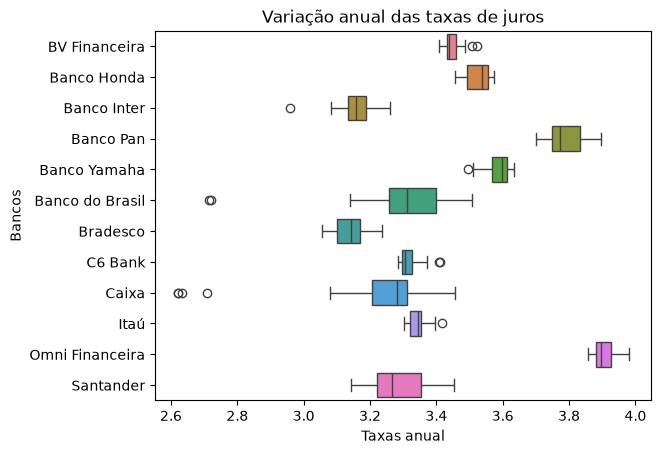

In [38]:
plt.title("Variação anual das taxas de juros")
sns.boxplot(
    data = df,
    y = "instituicao",
    x = np.log1p(df["taxa_juros_aa_pct"]),
    hue = "instituicao"
)
plt.xlabel("Taxas anual")
plt.ylabel("Bancos")

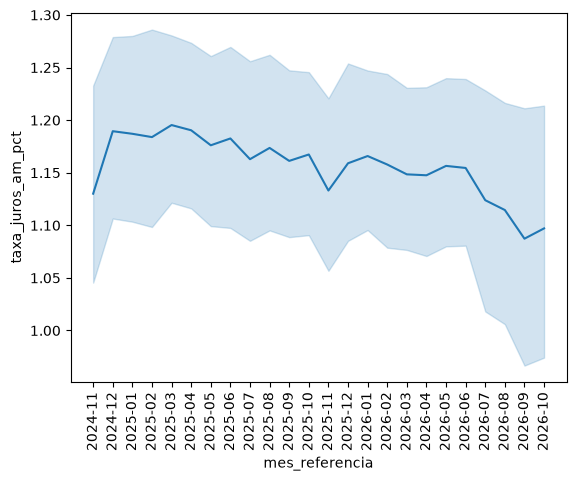

In [ ]:
sns.lineplot(
    data = df,
    x ="mes_referencia",
    y = np.log1p(df["taxa_juros_am_pct"])
)
plt.xticks(rotation = 90)
plt.show()

In [47]:
print(df["taxa_juros_am_pct"].mean())

2.2194425087108014


In [61]:
mercado = df.groupby("mes_referencia")["taxa_juros_am_pct"].mean().round(2).reset_index(name = "Média")
df = pd.merge(df,mercado)
calculo = (df["taxa_juros_am_pct"] - df["Média"]).reset_index(name = "Total")
print(calculo[calculo["Total"]> 0])
print(calculo[calculo["Total"]< 0])


     index  Total
0        0   0.07
1        1   0.12
3        3   0.86
4        4   0.33
10      10   1.23
..     ...    ...
275    275   0.15
276    276   0.33
278    278   0.86
279    279   0.58
285    285   1.30

[108 rows x 2 columns]
     index  Total
2        2  -0.73
5        5  -0.26
6        6  -0.52
7        7  -0.19
8        8  -0.55
..     ...    ...
281    281  -0.41
282    282  -0.11
283    283  -1.05
284    284  -0.06
286    286  -0.23

[178 rows x 2 columns]


In [71]:
primeiro_mes = df[df["mes_referencia"] =="2024-11"].sort_values(by = "instituicao",ascending= True)
ultimo_mes = df[df["mes_referencia"] =="2026-10"].sort_values(by = "instituicao", ascending= True)

print(ultimo_mes["taxa_juros_am_pct"] - primeiro_mes["taxa_juros_am_pct"])

0     NaN
1     NaN
2     NaN
3     NaN
4     NaN
5     NaN
6     NaN
7     NaN
8     NaN
9     NaN
10    NaN
11    NaN
275   NaN
276   NaN
277   NaN
278   NaN
279   NaN
280   NaN
281   NaN
282   NaN
283   NaN
284   NaN
285   NaN
286   NaN
Name: taxa_juros_am_pct, dtype: float64
